# Lab 4: Regression Analysis with Regularization
**Name:** Umama Azhar  

**Course:** MSCS 634 – Advanced Big Data and Data Mining 

**Assignment:** Lab 4 – Linear, Multiple, Polynomial, Ridge and Lasso Regression

**We will predict how much a diabetes patient’s disease has progressed after one year, using 10 health measurements like BMI and blood pressure. We’ll start with a straight line, then add more inputs, then curves, and finally add “penalties” (Ridge and Lasso) that stop the model from over-fitting.**

**Step 1 : Data Preparation**

In [1]:
# Importing the libraries we need and load the dataset.
# numpy: fast math on arrays of numbers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# load_diabetes: built-in sklearn function that returns the Diabetes dataset
from sklearn.datasets import load_diabetes

# Load the dataset. as_frame=True returns it as a pandas table
# instead of raw numpy arrays, which is easier to explore.
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Printing the table 
print("Shape:", df.shape)

# Printing the names of the 10 input features (age, sex, bmi, bp, s1-s6).
print("\nFeature names:", diabetes.feature_names)
df.head()

Shape: (442, 11)

Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:
# Checking data quality (missing values, duplicates)and getting summary statistics for every column.
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().round(3)

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


**Data cleaning:** The dataset has no missing values and no duplicate rows (442 patients, 10 features plus the target), so no cleaning was required. The features are already mean-centered and scaled by sklearn, so no extra scaling is needed either.

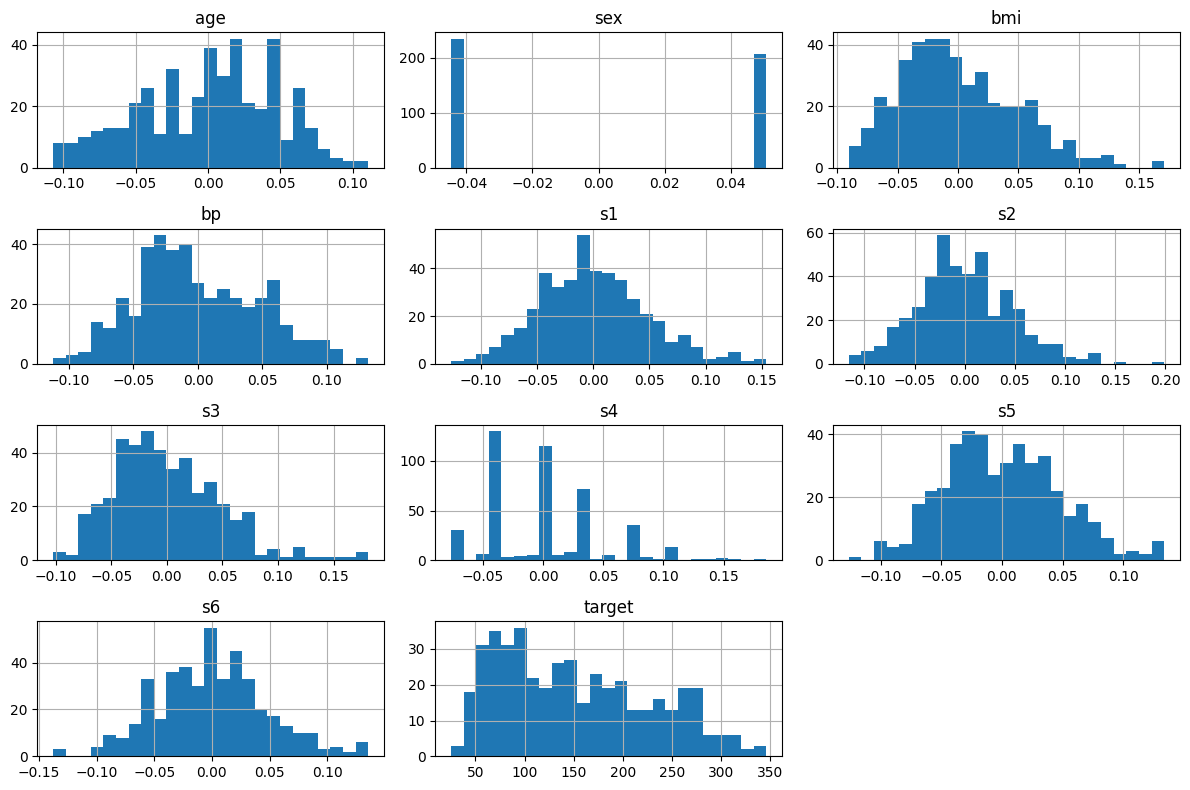

target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [3]:
# Seeing the shape of each variable and find which features relate most strongly to the target.
# hist() draws one histogram per column, showing how its values are spread.
# bins=25 splits each column's range into 25 bars.
# figsize sets the overall picture size (width, height in inches).
df.hist(figsize=(12, 8), bins=25)

# tight_layout() stops the subplot titles and labels from overlapping.
plt.tight_layout()

# show() displays the finished chart in the notebook.
plt.show()

# corr() computes how strongly every column moves together with every other
# (+1 = rise together, -1 = opposite, 0 = no linear relationship).
# ['target'] keeps only the correlations with the target column, and
# sort_values(ascending=False) lists the strongest positive ones first.
print(df.corr()['target'].sort_values(ascending=False))

**Step 2: Simple linear regression**

*I gave the model only one input (bmi) and it draws the best straight line through the points to predict disease progression. I held back 20% of patients as a test set the model never sees during training, so the score reflects how it does on new patients.*

In [4]:
#Picking one feature, splitting into train/test sets, and training a simple linear regression model.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# X = the input (independent variable).
X = df[['bmi']]
# y = the answer we want to predict (dependent variable).
y = df['target']

# Splitting : 80% of rows to train on, 20% held back to test on.
# random_state=42 fixes the shuffle so you get the same results every run.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# Creating the model, then fit() lets it learn the best line from the training data.
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

# The line is: prediction = intercept + slope * bmi
print("\nSlope (coefficient):", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Training rows: 353
Testing rows: 89

Slope (coefficient): 998.5776891375592
Intercept: 152.00335421448167


In [5]:
# Predicting on the unseen test data and score the model.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Asking the trained model to predict the target for the test patients.
y_pred_simple = simple_model.predict(X_test)

# MAE: average size of the error, in the target's own units.
mae = mean_absolute_error(y_test, y_pred_simple)

# MSE: average of the squared errors (punishes big misses harder).
mse = mean_squared_error(y_test, y_pred_simple)

# RMSE: square root of MSE, which puts the error back in the target's units.
rmse = np.sqrt(mse)

# R²: share of the variation in the target the model explains
# (1.0 = perfect, 0 = no better than always guessing the average).
r2 = r2_score(y_test, y_pred_simple)

print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

MAE : 52.26
MSE : 4061.83
RMSE: 63.73
R²  : 0.2334


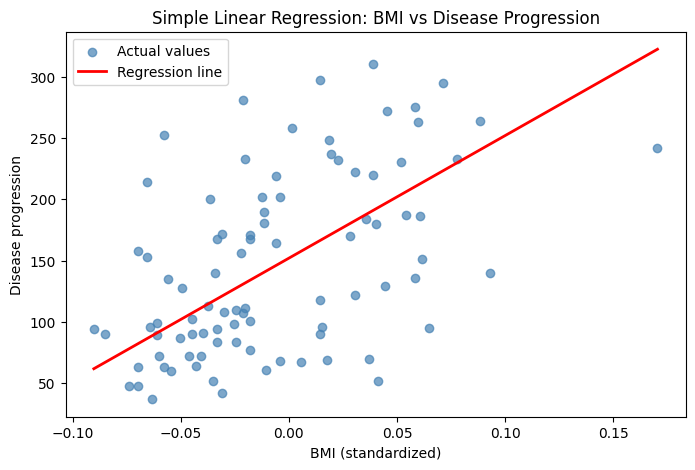

In [6]:
# Plotting the test data and the fitted line to see how well it fits.
plt.figure(figsize=(8, 5))

# Scatter plot of the real test data: bmi vs actual progression.
plt.scatter(X_test, y_test, color='steelblue', alpha=0.7, label='Actual values')

# Drawing the model's line. We sort by bmi so the line is drawn left to right.
order = X_test['bmi'].argsort()
plt.plot(X_test['bmi'].iloc[order], y_pred_simple[order],
         color='red', linewidth=2, label='Regression line')

plt.xlabel('BMI (standardized)')
plt.ylabel('Disease progression')
plt.title('Simple Linear Regression: BMI vs Disease Progression')
plt.legend()
plt.show()

**Simple linear regression (BMI only):** MAE = 52.26, MSE = 4061.83, RMSE = 63.73, R² = 0.2334. BMI has a clear positive relationship with disease progression, but on its own it explains only about 23% of the variance. This is the baseline for the later models.

**Step 3: Multiple regression**

*In this, instead of using only BMI, I will give the model all 10 measurements at once. It learns one weight per feature and combines them. Reusing the same train/test split so the comparison with Step 2 is fair.*

In [7]:
# Training a multiple regression model using ALL 10 features.
# X_multi = every column except the target (the 10 health measurements).
X_multi = df.drop(columns=['target'])

# Same split settings as Step 2 (test_size=0.2, random_state=42), so the
# same patients land in train/test and the comparison is fair.
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

# Creating and training the model. It now learns one weight (coefficient)
# per feature, plus one intercept.
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

# Showing each feature's learned weight. Bigger absolute value = stronger
# influence on the prediction (features are on the same scale, so this
# comparison is meaningful).
coef_table = pd.Series(multi_model.coef_, index=X_multi.columns)
print("Intercept:", round(multi_model.intercept_, 2))
print("\nCoefficients:")
print(coef_table.sort_values(ascending=False).round(2))

Intercept: 151.35

Coefficients:
s5     736.20
bmi    542.43
s2     518.06
bp     347.70
s4     275.32
s3     163.42
s6      48.67
age     37.90
sex   -241.96
s1    -931.49
dtype: float64


In [8]:
# Predicting on the test set and scoring the multiple regression model.
#Predicting the target for the unseen test patients using all 10 features.
y_pred_multi = multi_model.predict(X_test_m)

# Same four metrics as before:
mae_m = mean_absolute_error(y_test_m, y_pred_multi)   # average error size
mse_m = mean_squared_error(y_test_m, y_pred_multi)    # average squared error
rmse_m = np.sqrt(mse_m)                               # error in original units
r2_m = r2_score(y_test_m, y_pred_multi)               # share of variance explained

print(f"MAE : {mae_m:.2f}")
print(f"MSE : {mse_m:.2f}")
print(f"RMSE: {rmse_m:.2f}")
print(f"R²  : {r2_m:.4f}")

# Side-by-side with Step 2 so the improvement is visible.
print(f"\nSimple (BMI only) R²: {r2:.4f}  ->  Multiple (10 features) R²: {r2_m:.4f}")

MAE : 42.79
MSE : 2900.19
RMSE: 53.85
R²  : 0.4526

Simple (BMI only) R²: 0.2334  ->  Multiple (10 features) R²: 0.4526


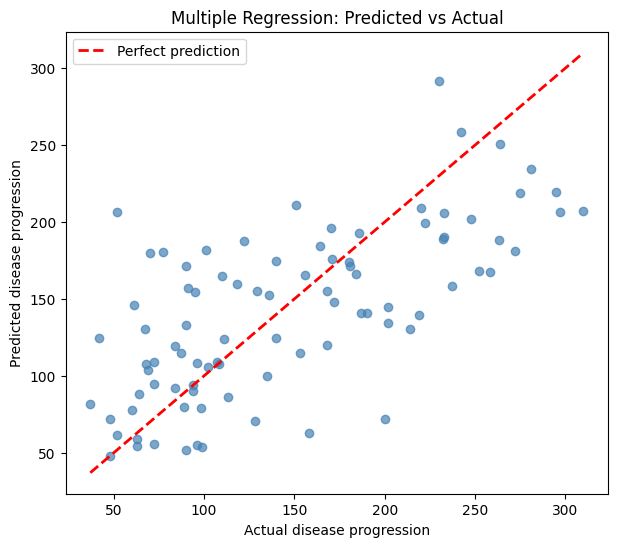

In [9]:
#Plotting predicted vs actual values. A perfect model would put every point on the diagonal line.
plt.figure(figsize=(7, 6))

# Each dot is one test patient: x = true value, y = model's prediction.
plt.scatter(y_test_m, y_pred_multi, color='steelblue', alpha=0.7)

# The red dashed diagonal is the "perfect prediction" line (predicted = actual).
low, high = y_test_m.min(), y_test_m.max()
plt.plot([low, high], [low, high], color='red', linestyle='--', linewidth=2,
         label='Perfect prediction')

plt.xlabel('Actual disease progression')
plt.ylabel('Predicted disease progression')
plt.title('Multiple Regression: Predicted vs Actual')
plt.legend()
plt.show()

**Multiple regression (all 10 features):** MAE = 42.79, MSE = 2900.19, RMSE = 53.85, R² = 0.4526. Using all features improved R² from 0.2334 (BMI only) to 0.4526. The coefficients for s1 (-931) and s2 (+518) are large with opposite signs, which suggests these features are highly correlated with each other (multicollinearity), making their individual weights unstable. Regularization in Step 5 should help with this.

**Step 4: Polynomial regression**

*Polynomial regression lets the model bend. Besides each feature, it also creates squared terms (like bmi²) and combinations (like bmi × bp), so it can fit curves instead of flat planes. Degree 1 is just the multiple regression i already have. Higher degrees add more flexibility, and too much flexibility means the model memorizes the training data (overfitting) instead of learning the real pattern. Cell 10 shows this with a table, and Cell 12 shows it as pictures.*

In [10]:
# Training polynomial regression models of increasing degree using ALL 10 features, and compare train vs test scores.
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# collecting one row of results per degree here.
results = []

for degree in [1, 2, 3]:
    # A pipeline chains two steps:
    #   1) PolynomialFeatures builds the squared/cubed/combination columns
    #   2) LinearRegression fits a normal linear model on those new columns
    # include_bias=False skips a constant column (LinearRegression adds its own).
    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    # Learning from the training data only.
    poly_model.fit(X_train_m, y_train_m)

    # Predicting on BOTH sets: training (data it has seen) and testing (unseen).
    train_pred = poly_model.predict(X_train_m)
    test_pred = poly_model.predict(X_test_m)

    # Storing the scores. A big gap (high train R², low test R²) means overfitting.
    results.append({
        'Degree': degree,
        'Num features': poly_model[0].n_output_features_,
        'Train R²': r2_score(y_train_m, train_pred),
        'Test R²': r2_score(y_test_m, test_pred),
        'Test MAE': mean_absolute_error(y_test_m, test_pred),
        'Test MSE': mean_squared_error(y_test_m, test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test_m, test_pred)),
    })

# Turning the list into a table for easy reading.
poly_results = pd.DataFrame(results)
poly_results.round(4)

,Degree,Num features,Train R²,Test R²,Test MAE,Test MSE,Test RMSE
0,1,10,0.5279,0.4526,42.7941,2900.1936,53.8534
1,2,65,0.6062,0.4156,43.5817,3096.0283,55.6420
2,3,285,0.8566,-5.2120,121.9767,32911.9607,181.4165


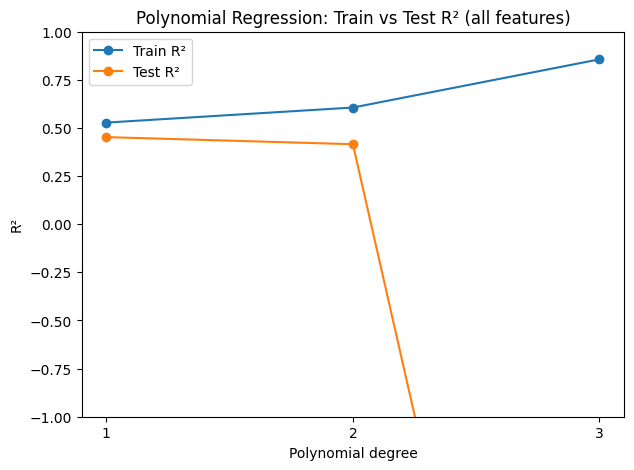

In [11]:
# Visualizing how train and test R² change as the degree grows.
# Train R² rising while test R² falls is the overfitting signature.
plt.figure(figsize=(7, 5))

# One line for the training score, one for the test score.
plt.plot(poly_results['Degree'], poly_results['Train R²'], marker='o', label='Train R²')
plt.plot(poly_results['Degree'], poly_results['Test R²'], marker='o', label='Test R²')

# Limiting the y-axis so a very negative test score doesn't squash the chart.
# (If a value is below -1, it runs off the bottom; read it from the table.)
plt.ylim(-1, 1)
plt.xticks([1, 2, 3])
plt.xlabel('Polynomial degree')
plt.ylabel('R²')
plt.title('Polynomial Regression: Train vs Test R² (all features)')
plt.legend()
plt.show()

Degree  1 -> Train R²: 0.3657 | Test R²: 0.2334
Degree  3 -> Train R²: 0.3667 | Test R²: 0.2329
Degree 10 -> Train R²: 0.3721 | Test R²: 0.2489


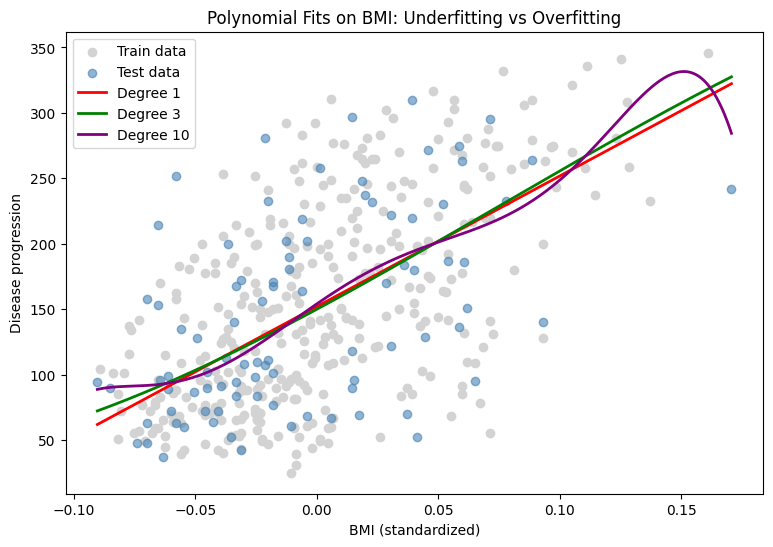

In [12]:
# Showing what different degrees look like as actual curves, using just BMI so we can draw them in 2D. Reuses the Step 2 split (X_train, X_test, y_train, y_test).
# A smooth set of BMI values to draw each curve across the full range.
x_grid = pd.DataFrame(
    np.linspace(X['bmi'].min(), X['bmi'].max(), 300), columns=['bmi']
)

plt.figure(figsize=(9, 6))

# Light dots: the real training and testing patients.
plt.scatter(X_train, y_train, color='lightgray', label='Train data')
plt.scatter(X_test, y_test, color='steelblue', alpha=0.6, label='Test data')

# Degree 1 = straight line (likely too simple), 3 = gentle curve,
# 10 = very flexible (likely overfits).
for degree, color in [(1, 'red'), (3, 'green'), (10, 'purple')]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)

    # Printing train and test R² so you can compare with the picture.
    print(f"Degree {degree:2d} -> Train R²: {model.score(X_train, y_train):.4f} | "
          f"Test R²: {model.score(X_test, y_test):.4f}")

    # Drawing the curve the model learned.
    plt.plot(x_grid['bmi'], model.predict(x_grid), color=color,
             linewidth=2, label=f'Degree {degree}')

plt.xlabel('BMI (standardized)')
plt.ylabel('Disease progression')
plt.title('Polynomial Fits on BMI: Underfitting vs Overfitting')
plt.legend()
plt.show()

**Polynomial regression:** With all 10 features, degree 1 scored test R² = 0.4526, degree 2 dropped to 0.4156 (train R² rose to 0.6062), and degree 3 collapsed to -5.21 (train R² = 0.8566, 285 features on 353 training rows), a clear case of overfitting. With BMI alone, degrees 1, 3 and 10 scored almost the same on the test set (about 0.23-0.25) because the relationship is nearly linear, but the degree 10 curve bends sharply at high BMI values where there is little data. Degree 1 underfits only in the sense that it is stiff; here the extra flexibility did not help.

**Step 5: Ridge and Lasso regression**

*In this , Both models are multiple regression with a penalty for large coefficients. That should calm down the s1 = -931 and s2 = +518 situation. The strength of the penalty is a dial called alpha. Ridge shrinks all coefficients toward zero but keeps every feature. Lasso can shrink some coefficients exactly to zero, which removes those features. A small alpha behaves like plain multiple regression, and a large alpha shrinks so much the model underfits. Our features are already standardized, so no extra scaling is needed.*

In [13]:
# Training Ridge and Lasso at several alpha (penalty strength) values and see how the test scores change.
from sklearn.linear_model import Ridge, Lasso

rows = []

for alpha in [0.001, 0.01, 0.1, 1, 10]:
    for name, model in [('Ridge', Ridge(alpha=alpha)),
                        # max_iter raised so Lasso has enough steps to converge
                        ('Lasso', Lasso(alpha=alpha, max_iter=10000))]:
        # Learning from the training data only (same split as Step 3).
        model.fit(X_train_m, y_train_m)

        # Scoring on the unseen test data.
        pred = model.predict(X_test_m)

        rows.append({
            'Model': name,
            'Alpha': alpha,
            'MAE': mean_absolute_error(y_test_m, pred),
            'MSE': mean_squared_error(y_test_m, pred),
            'RMSE': np.sqrt(mean_squared_error(y_test_m, pred)),
            'R²': r2_score(y_test_m, pred),
            # How many coefficients were shrunk to exactly zero (Lasso can do this).
            'Zeroed features': int((model.coef_ == 0).sum()),
        })

reg_results = pd.DataFrame(rows)
reg_results.round(4)

,Model,Alpha,MAE,MSE,RMSE,R²,Zeroed features
0,Ridge,0.001,42.8031,2895.8212,53.8128,0.4534,0
1,Lasso,0.001,42.7962,2896.4098,53.8183,0.4533,0
2,Ridge,0.010,42.8369,2882.2902,53.6870,0.4560,0
3,Lasso,0.010,42.8318,2878.5594,53.6522,0.4567,0
4,Ridge,0.100,42.9969,2856.4869,53.4461,0.4609,0
5,Lasso,0.100,42.8544,2798.1935,52.8980,0.4719,3
6,Ridge,1.000,46.1389,3077.4159,55.4745,0.4192,0
7,Lasso,1.000,49.7303,3403.5757,58.3402,0.3576,7
8,Ridge,10.000,58.0308,4443.9526,66.6630,0.1612,0
9,Lasso,10.000,64.0065,5361.5335,73.2225,-0.0120,10


In [14]:
# Letting cross-validation choose the best alpha for each model,then compare coefficients side by side with plain regression.
from sklearn.linear_model import RidgeCV, LassoCV

# RidgeCV / LassoCV try many alphas using 5-fold cross-validation on the
# TRAINING data only, then keep the best one. The test set stays untouched.
ridge_cv = RidgeCV(alphas=np.logspace(-3, 1, 50)).fit(X_train_m, y_train_m)
lasso_cv = LassoCV(alphas=np.logspace(-3, 1, 50), cv=5,
                   max_iter=10000).fit(X_train_m, y_train_m)

print("Best Ridge alpha:", round(ridge_cv.alpha_, 4))
print("Best Lasso alpha:", round(lasso_cv.alpha_, 4))

# Scoring all three models on the same test set.
for name, model in [('Multiple (no penalty)', multi_model),
                    ('Ridge', ridge_cv), ('Lasso', lasso_cv)]:
    pred = model.predict(X_test_m)
    print(f"{name:22s} MAE {mean_absolute_error(y_test_m, pred):6.2f} | "
          f"MSE {mean_squared_error(y_test_m, pred):8.2f} | "
          f"RMSE {np.sqrt(mean_squared_error(y_test_m, pred)):6.2f} | "
          f"R² {r2_score(y_test_m, pred):.4f}")

# Coefficients side by side: watch s1 and s2 shrink, and look for zeros in Lasso.
coef_compare = pd.DataFrame({
    'Multiple': multi_model.coef_,
    'Ridge': ridge_cv.coef_,
    'Lasso': lasso_cv.coef_,
}, index=X_multi.columns)
coef_compare.round(2)

Best Ridge alpha: 0.0026
Best Lasso alpha: 0.0754
Multiple (no penalty)  MAE  42.79 | MSE  2900.19 | RMSE  53.85 | R² 0.4526
Ridge                  MAE  42.81 | MSE  2891.32 | RMSE  53.77 | R² 0.4543
Lasso                  MAE  42.78 | MSE  2800.70 | RMSE  52.92 | R² 0.4714


,Multiple,Ridge,Lasso
age,37.90,39.15,0.00
sex,-241.96,-240.49,-170.09
bmi,542.43,545.22,554.31
bp,347.70,345.60,312.65
s1,-931.49,-707.44,-104.40
s2,518.06,343.65,-0.00
s3,163.42,63.15,-235.87
s4,275.32,243.80,0.00
s5,736.20,649.58,462.16
s6,48.67,51.12,37.82


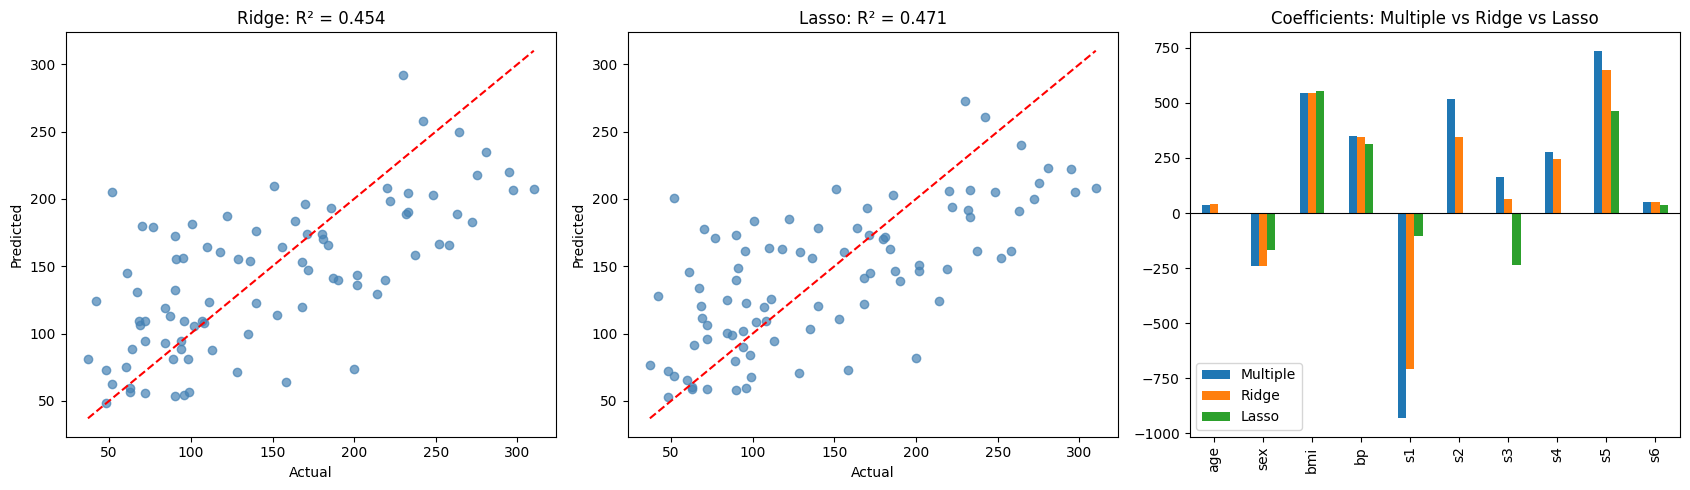

In [15]:
# Plotting predicted vs actual for Ridge and Lasso, and showing how
# coefficients compare across the three models.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panels 1 and 2: predicted vs actual (closer to the red line = better).
for ax, name, model in [(axes[0], 'Ridge', ridge_cv), (axes[1], 'Lasso', lasso_cv)]:
    pred = model.predict(X_test_m)
    ax.scatter(y_test_m, pred, color='steelblue', alpha=0.7)
    low, high = y_test_m.min(), y_test_m.max()
    ax.plot([low, high], [low, high], color='red', linestyle='--')
    ax.set_title(f"{name}: R² = {r2_score(y_test_m, pred):.3f}")
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')

# Panel 3: grouped bars of coefficients, one group per feature.
coef_compare.plot(kind='bar', ax=axes[2])
axes[2].set_title('Coefficients: Multiple vs Ridge vs Lasso')
axes[2].axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

**Effect of alpha:** Alpha controls the penalty strength. At very small alpha (0.001) Ridge and Lasso behave like plain multiple regression (R² ≈ 0.453). At moderate alpha (0.1), Lasso performed best (R² = 0.4719, RMSE = 52.90) and removed 3 features. At large alpha (10) the penalty dominates: Ridge dropped to R² = 0.1612 and Lasso zeroed all 10 coefficients (R² = -0.012), which is underfitting.

**Ridge vs Lasso:** With cross-validated alphas (Ridge 0.0026, Lasso 0.0754), Ridge scored R² = 0.4543 and Lasso scored R² = 0.4714, compared with 0.4526 for plain multiple regression. Ridge shrank the large, opposite-signed s1 (-931 to -707) and s2 (518 to 344) coefficients but kept all features. Lasso set age, s2 and s4 to exactly zero and shrank s1 to -104, effectively selecting a smaller set of features. This suggests s1, s2 and s4 carry overlapping information with other features.

In [16]:
# Collecting train/test scores for every model in one table.
# Refitting polynomial models (degree 2 and 3, all features) because the
# earlier loop did not keep them.
poly2 = make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())
poly3 = make_pipeline(PolynomialFeatures(3, include_bias=False), LinearRegression())
poly2.fit(X_train_m, y_train_m)
poly3.fit(X_train_m, y_train_m)

# Each entry: model name -> (fitted model, train features, test features)
# The BMI-only model uses the one-feature data; all others use all 10 features.
all_models = {
    'Simple (BMI only)': (simple_model, X_train, X_test),
    'Multiple (10 features)': (multi_model, X_train_m, X_test_m),
    'Polynomial deg 2': (poly2, X_train_m, X_test_m),
    'Polynomial deg 3': (poly3, X_train_m, X_test_m),
    'Ridge (CV alpha)': (ridge_cv, X_train_m, X_test_m),
    'Lasso (CV alpha)': (lasso_cv, X_train_m, X_test_m),
}

rows = []
for name, (model, Xtr, Xte) in all_models.items():
    # y_train / y_test are the same patients for every model (same split).
    test_pred = model.predict(Xte)
    rows.append({
        'Model': name,
        'Train R²': r2_score(y_train, model.predict(Xtr)),
        'Test R²': r2_score(y_test, test_pred),
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Test MSE': mean_squared_error(y_test, test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
    })

summary = pd.DataFrame(rows).set_index('Model')
summary.round(4)

,Train R²,Test R²,Test MAE,Test MSE,Test RMSE
Model,,,,,
Simple (BMI only),0.3657,0.2334,52.2600,4061.8259,63.7325
Multiple (10 features),0.5279,0.4526,42.7941,2900.1936,53.8534
Polynomial deg 2,0.6062,0.4156,43.5817,3096.0283,55.6420
Polynomial deg 3,0.8566,-5.2120,121.9767,32911.9607,181.4165
Ridge (CV alpha),0.5276,0.4543,42.8133,2891.3230,53.7710
Lasso (CV alpha),0.5193,0.4714,42.7840,2800.6992,52.9216


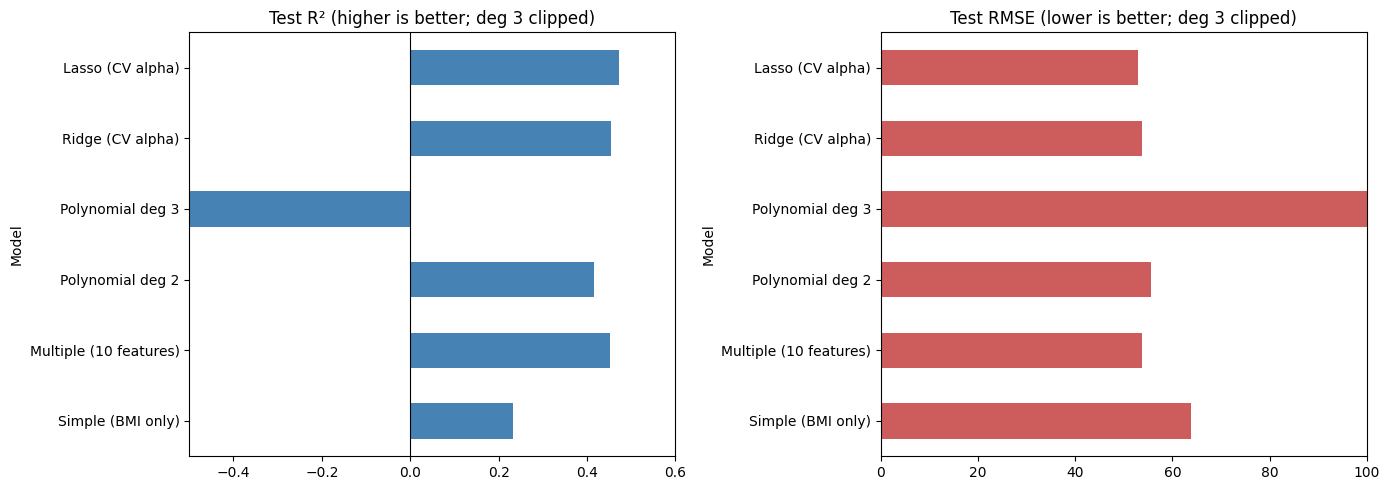

In [17]:
#  Chart the test R² and test RMSE of every model. Higher R² and lower RMSE are better.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: test R². Polynomial deg 3 is very negative, so we clip the axis
# and read its exact value from the table.
summary['Test R²'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_xlim(-0.5, 0.6)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Test R² (higher is better; deg 3 clipped)')

# Right: test RMSE, clipped for the same reason.
summary['Test RMSE'].plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_xlim(0, 100)
axes[1].set_title('Test RMSE (lower is better; deg 3 clipped)')

plt.tight_layout()
plt.show()

## Step 6: Model Comparison and Analysis

| Model | Test R² | Test RMSE |
|---|---|---|
| Simple (BMI only) | 0.2334 | 63.73 |
| Multiple (10 features) | 0.4526 | 53.85 |
| Polynomial degree 2 | 0.4156 | 55.64 |
| Polynomial degree 3 | -5.2120 | 181.42 |
| Ridge (CV alpha) | 0.4543 | 53.77 |
| Lasso (CV alpha) | 0.4714 | 52.92 |

**How well each model performed:** Lasso performed best (R² = 0.4714, RMSE = 52.92), followed closely by Ridge and plain multiple regression (about 0.45). The BMI-only model explained only about 23% of the variance. Even the best model leaves more than half of the variation unexplained, so these 10 measurements are only a partial predictor of disease progression.

**Overfitting and underfitting:** Polynomial degree 3 overfit badly. Its train R² (0.8566) was far above its test R² (-5.21), because 285 features were fit on only 353 training rows. Degree 2 also lost a little test accuracy compared with degree 1. The BMI-only model is the underfit end: it is too simple to capture much of the signal. Lasso and Ridge handled overfitting best because the penalty keeps coefficients small.

**Effect of regularization:** Ridge shrank the correlated s1 and s2 coefficients without removing features. Lasso removed age, s2 and s4 and still achieved the best test score, so a simpler model did at least as well as the full one. The improvement over plain multiple regression is modest (about +0.02 R²) and comes from a single train/test split of 89 patients, so it should be treated as suggestive rather than conclusive.

**Insights about the Diabetes dataset:** BMI, s5 and blood pressure (bp) are the strongest predictors. The blood-serum measurements s1 and s2 overlap heavily (multicollinearity), which produced large opposite-signed coefficients in plain regression. The relationship between BMI and progression is close to linear, so polynomial terms added complexity without adding accuracy. With only 442 patients, flexible models overfit quickly.